In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Trần Công Nhân - 6451071054")

# Đọc dữ liệu (thay bằng tên file CSV của Bài 5 nếu khác)
df = sns.load_dataset('titanic')
# Nếu dùng file CSV tải lên Colab thì mở dòng dưới:
# df = pd.read_csv('titanic.csv')

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Trần Công Nhân - 6451071054
Kích thước dữ liệu: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
print("Trần Công Nhân - 6451071054")

print("Thông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị thiếu ở từng cột:")
print(df.isnull().sum())

# Giữ lại các cột đặc trưng chính (nếu dùng bộ Titanic của seaborn)
cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df[cols].copy()

# Điền giá trị thiếu: tuổi điền trung vị, cảng lên tàu điền giá trị phổ biến nhất
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

print("\nSố giá trị thiếu sau khi xử lý:")
print(df.isnull().sum())

Trần Công Nhân - 6451071054
Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Số lượng giá trị thiếu ở từng c

Trần Công Nhân - 6451071054


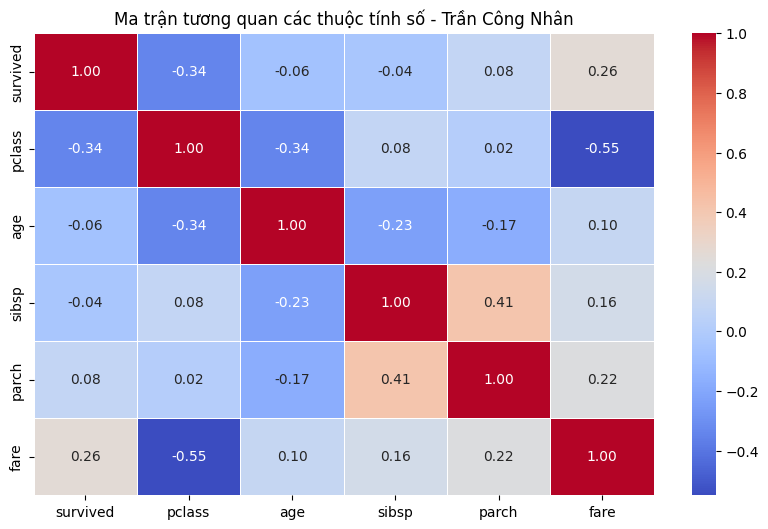

In [3]:
print("Trần Công Nhân - 6451071054")

plt.figure(figsize=(10, 6))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Ma trận tương quan các thuộc tính số - Trần Công Nhân")
plt.show()

In [4]:
print("Trần Công Nhân - 6451071054")

X = df.drop('survived', axis=1)
y = df['survived']

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("\nPhân bố nhãn lớp y (0: Không qua khỏi, 1: Sống sót):")
print(y.value_counts())

Trần Công Nhân - 6451071054
Kích thước X: (891, 7)
Kích thước y: (891,)

Phân bố nhãn lớp y (0: Không qua khỏi, 1: Sống sót):
survived
0    549
1    342
Name: count, dtype: int64


In [5]:
print("Trần Công Nhân - 6451071054")

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("Các cột dạng phi số cần chuyển đổi:", categorical_cols)

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print("\nDữ liệu X sau khi mã hóa sang dạng số:")
display(X.head())

Trần Công Nhân - 6451071054
Các cột dạng phi số cần chuyển đổi: ['sex', 'embarked']

Dữ liệu X sau khi mã hóa sang dạng số:


,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,True,False,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,False,True
3,1,35.0,1,0,53.1000,False,False,True
4,3,35.0,0,0,8.0500,True,False,True


In [6]:
print("Trần Công Nhân - 6451071054")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)

Trần Công Nhân - 6451071054
Kích thước X_train: (623, 8)
Kích thước X_test: (268, 8)


Trần Công Nhân - 6451071054
Độ chính xác mô hình ID3: 0.7575

Báo cáo phân lớp - ID3:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80       157
           1       0.73      0.66      0.69       111

    accuracy                           0.76       268
   macro avg       0.75      0.74      0.75       268
weighted avg       0.76      0.76      0.76       268



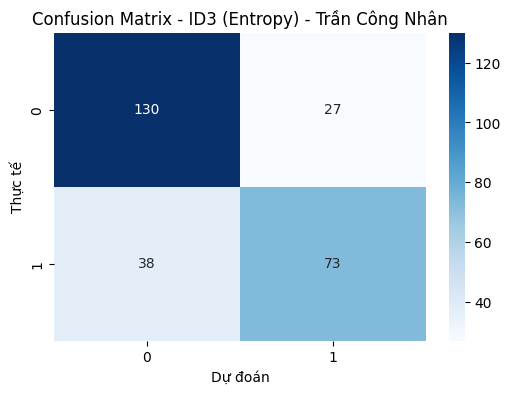

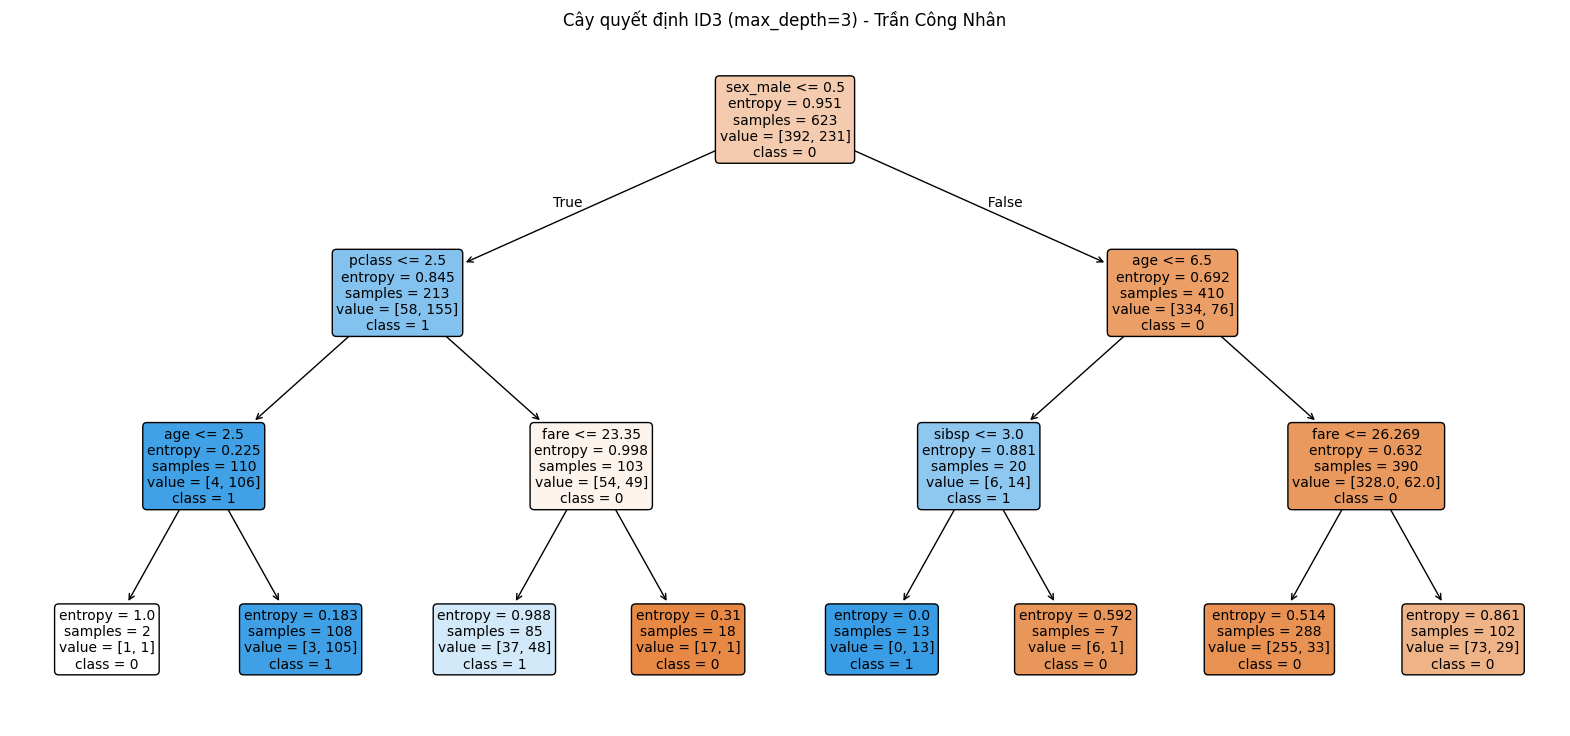

In [7]:
print("Trần Công Nhân - 6451071054")

id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3_model.fit(X_train, y_train)

y_pred_id3 = id3_model.predict(X_test)
acc_id3 = accuracy_score(y_test, y_pred_id3)

print(f"Độ chính xác mô hình ID3: {acc_id3:.4f}")
print("\nBáo cáo phân lớp - ID3:")
print(classification_report(y_test, y_pred_id3))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_id3), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - ID3 (Entropy) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định ID3 (max_depth=3)
id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
id3_vis.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(id3_vis, feature_names=X_train.columns, class_names=['0', '1'], filled=True, rounded=True, fontsize=10)
plt.title("Cây quyết định ID3 (max_depth=3) - Trần Công Nhân")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác mô hình CART: 0.7463

Báo cáo phân lớp - CART:
              precision    recall  f1-score   support

           0       0.78      0.79      0.78       157
           1       0.70      0.68      0.69       111

    accuracy                           0.75       268
   macro avg       0.74      0.74      0.74       268
weighted avg       0.75      0.75      0.75       268



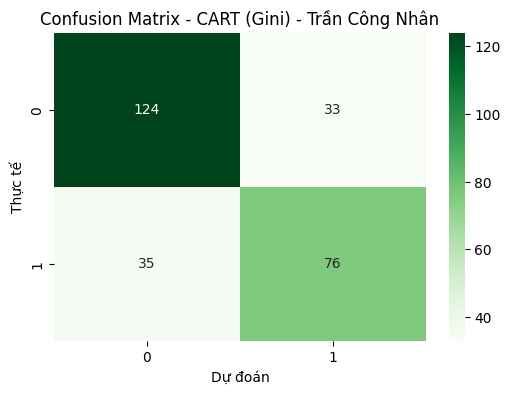

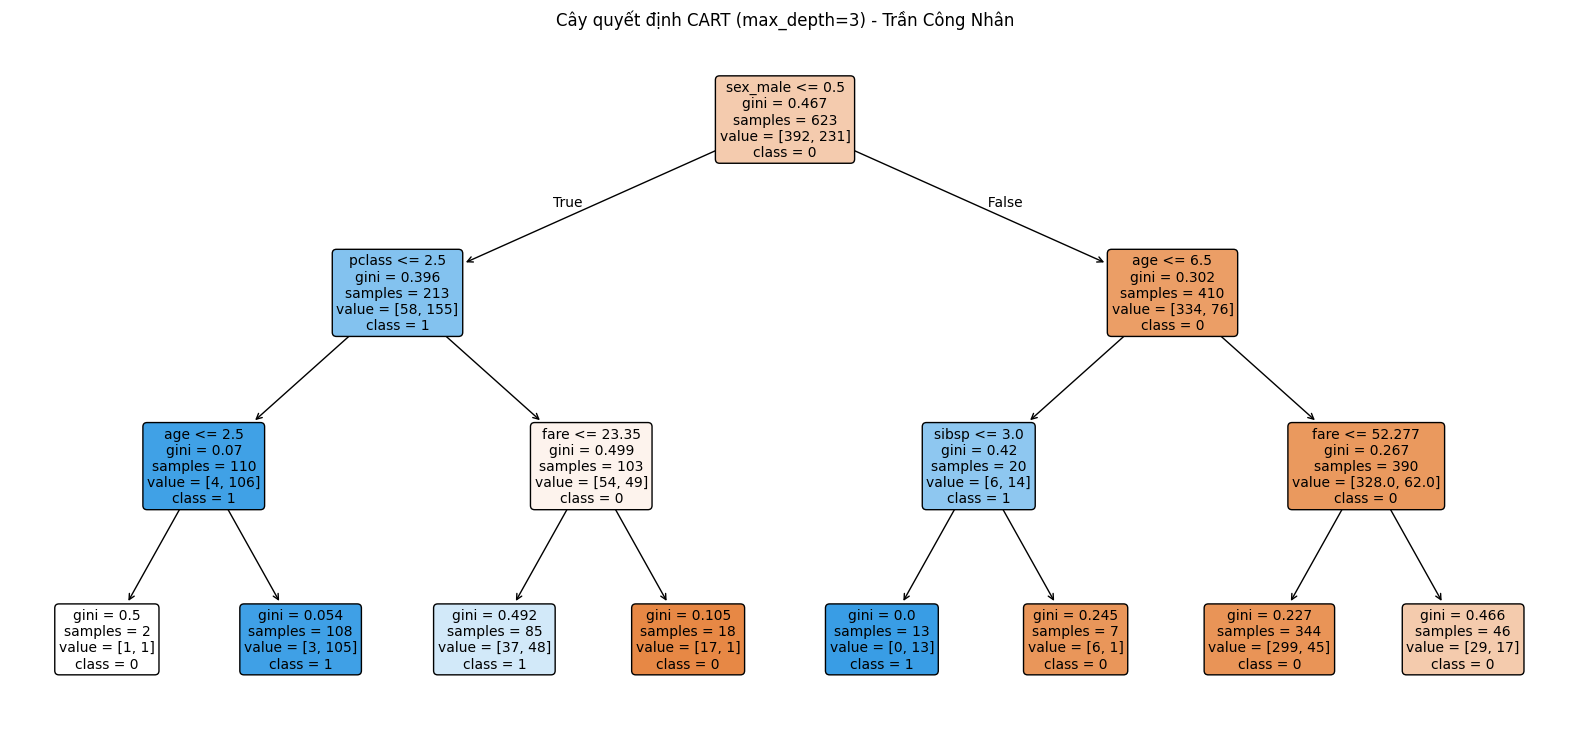

In [8]:
print("Trần Công Nhân - 6451071054")

cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_model.fit(X_train, y_train)

y_pred_cart = cart_model.predict(X_test)
acc_cart = accuracy_score(y_test, y_pred_cart)

print(f"Độ chính xác mô hình CART: {acc_cart:.4f}")
print("\nBáo cáo phân lớp - CART:")
print(classification_report(y_test, y_pred_cart))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_cart), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - CART (Gini) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định CART (max_depth=3)
cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
cart_vis.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(cart_vis, feature_names=X_train.columns, class_names=['0', '1'], filled=True, rounded=True, fontsize=10)
plt.title("Cây quyết định CART (max_depth=3) - Trần Công Nhân")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác mô hình Naive Bayes: 0.7948

Báo cáo phân lớp - Naive Bayes:
              precision    recall  f1-score   support

           0       0.82      0.83      0.83       157
           1       0.75      0.75      0.75       111

    accuracy                           0.79       268
   macro avg       0.79      0.79      0.79       268
weighted avg       0.79      0.79      0.79       268



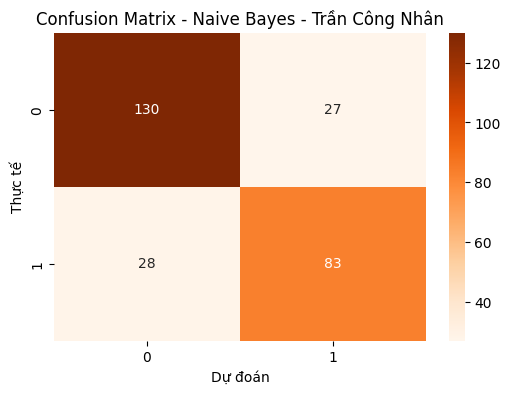

In [9]:
print("Trần Công Nhân - 6451071054")

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Độ chính xác mô hình Naive Bayes: {acc_nb:.4f}")
print("\nBáo cáo phân lớp - Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Naive Bayes - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Trần Công Nhân - 6451071054


,Mô hình,Accuracy
0,ID3 (Entropy),0.757463
1,CART (Gini),0.746269
2,Naive Bayes,0.794776


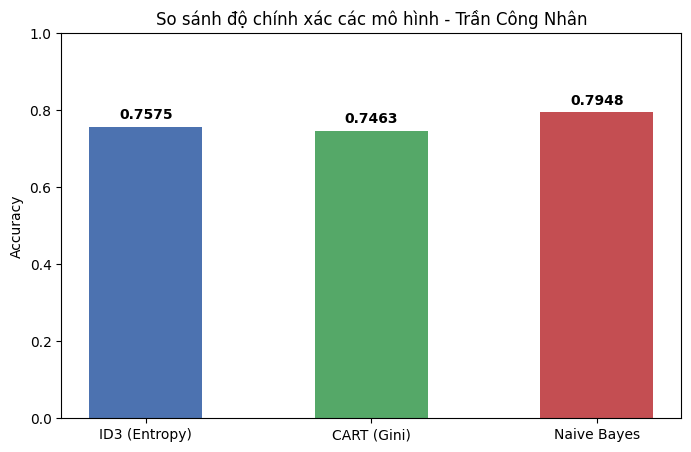

In [10]:
print("Trần Công Nhân - 6451071054")

model_names = ['ID3 (Entropy)', 'CART (Gini)', 'Naive Bayes']
accuracies = [acc_id3, acc_cart, acc_nb]

df_results = pd.DataFrame({'Mô hình': model_names, 'Accuracy': accuracies})
display(df_results)

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies, color=['#4C72B0', '#55A868', '#C44E52'], width=0.5)
plt.ylim(0, 1.0)
plt.ylabel('Accuracy')
plt.title('So sánh độ chính xác các mô hình - Trần Công Nhân')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', fontweight='bold')

plt.show()